# Content-based recommenders
Items are represented by their metadata text with TF-IDF, GloVe, BERT and RoBERTa.

In [1]:
import sys
sys.path.append("..")

from hybrid_recommenders.data import load_train_and_test_ratings

DATA_FOLDER = "../data"
train_df, test_df = load_train_and_test_ratings(f"{DATA_FOLDER}/train_video_games.parquet",
                                                f"{DATA_FOLDER}/test_video_games.parquet")

from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

from hybrid_recommenders.content_based import (
    fit_tfidf, glove_embeddings, item_similarity_table, load_or_compute_embeddings,
    recommend_by_profile_similarity, transformer_embeddings,
)
from hybrid_recommenders.data import load_item_metadata
from hybrid_recommenders.evaluation import compare_models
from hybrid_recommenders.plotting import plot_similarity_heatmap
from hybrid_recommenders.text_preprocessing import (
    build_item_corpus, lightly_clean_column, preprocess_column, vocabulary_size_per_preprocessing_step,
)

item_metadata_df = load_item_metadata(f"{DATA_FOLDER}/meta_video_games.parquet", train_df, test_df)
item_ids = item_metadata_df["item_id"].tolist()
item_titles = item_metadata_df.set_index("item_id")["title"].to_dict()

## Preprocessing
The most common first and last sentences of the descriptions are Amazon boilerplate, which we remove (see `AMAZON_BOILERPLATE_PHRASES`).

In [2]:
first_sentences = [description[0] for description in item_metadata_df["description"] if len(description) > 0]
last_sentences = [description[-1] for description in item_metadata_df["description"] if len(description) > 0]
print(Counter(first_sentences).most_common(7))
print(Counter(last_sentences).most_common(15))

[('Product Description', 278), ('Product description', 33), ('From the Manufacturer', 29), ('Amazon.com', 9), ('view larger', 3), ('View larger', 3), ('*The DLC (Downloadable Content), Trials/Subscriptions may or may not be included and are not guaranteed to work*', 3)]
[('Additional Screenshots', 46), ('account required for game activation and installation', 28), ('.', 24), ('View larger', 19), ('See more', 17), ('view larger', 14), ('From the Manufacturer', 6), ('PlayStation 3', 4), ('View larger.', 3), ('Screenshots', 3), ('account required to download and install.', 3), ('*The DLC (Downloadable Content), Trials/Subscriptions may or may not be included and are not guaranteed to work*', 3), ('Amazon.com', 2), ("In Resident Evil 4 you'll know a new type of horror, as the classic survival-horror action returns with all-new characters, controls and storylines. We last saw Leon S. Kennedy in Resident Evil 2 - a rookie cop in Raccoon City, fighting to stay alive. That was six years ago. S

In [3]:
pd.Series(vocabulary_size_per_preprocessing_step(item_metadata_df["description"]), name="vocabulary size")

raw                    22973
lowercased             18528
lemmatized             16641
stopwords removed      16506
punctuation removed    16480
Name: vocabulary size, dtype: int64

## Comparing the representations on descriptions only
BERT and RoBERTa get the lowercased descriptions, since they have their own tokenizers.

In [4]:
processed_descriptions = preprocess_column(item_metadata_df["description"])
lightly_cleaned_descriptions = lightly_clean_column(item_metadata_df["description"])

description_tfidf_matrix, _ = fit_tfidf(processed_descriptions)
print(description_tfidf_matrix.shape)

(932, 18403)


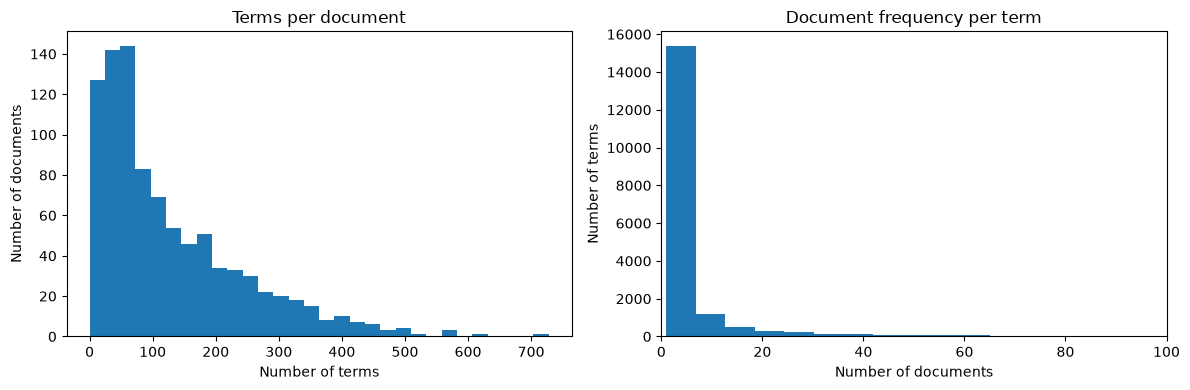

In [5]:
term_is_present = description_tfidf_matrix.toarray() > 0

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(term_is_present.sum(axis=1), bins=30)
axes[0].set(xlabel="Number of terms", ylabel="Number of documents", title="Terms per document")
axes[1].hist(term_is_present.sum(axis=0), bins=100)
axes[1].set(xlabel="Number of documents", ylabel="Number of terms", title="Document frequency per term", xlim=(0, 100))
plt.tight_layout()
plt.show()

In [6]:
description_representations = {
    "TF-IDF": description_tfidf_matrix,
    "GloVe": load_or_compute_embeddings("../cache/glove_descriptions.npy",
                                        lambda: glove_embeddings(processed_descriptions)),
    "BERT": load_or_compute_embeddings("../cache/bert_descriptions.npy",
                                       lambda: transformer_embeddings(lightly_cleaned_descriptions, "bert-base-uncased")),
    "RoBERTa": load_or_compute_embeddings("../cache/roberta_descriptions.npy",
                                          lambda: transformer_embeddings(lightly_cleaned_descriptions, "roberta-base")),
}

[==================================================] 100.0% 128.1/128.1MB downloaded


/opt/anaconda3/envs/hybrid-recsys/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7331.86it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when lo

Hand-picked games: a franchise (Final Fantasy), other PlayStation 2 games, Game Boy, Xbox, GameCube and an accessory.

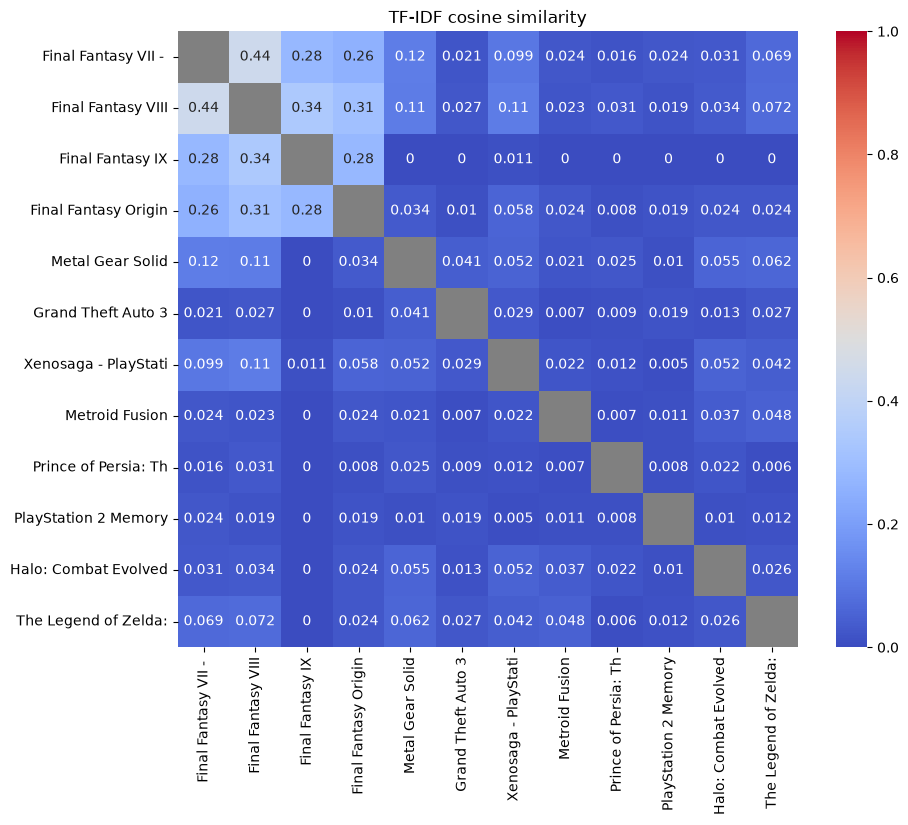

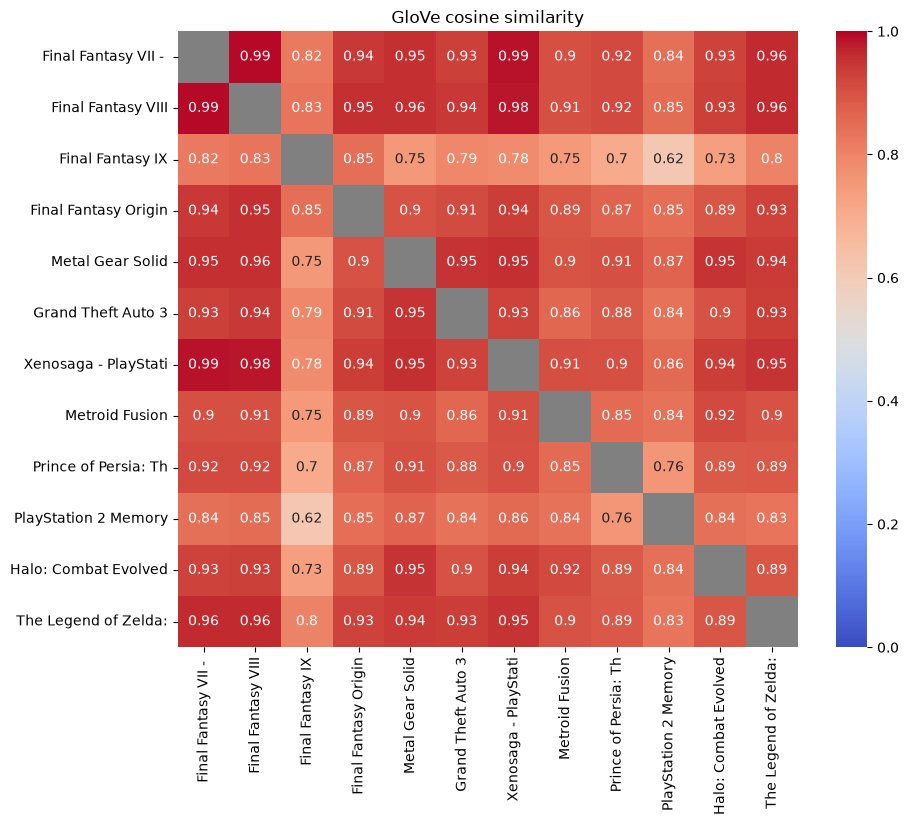

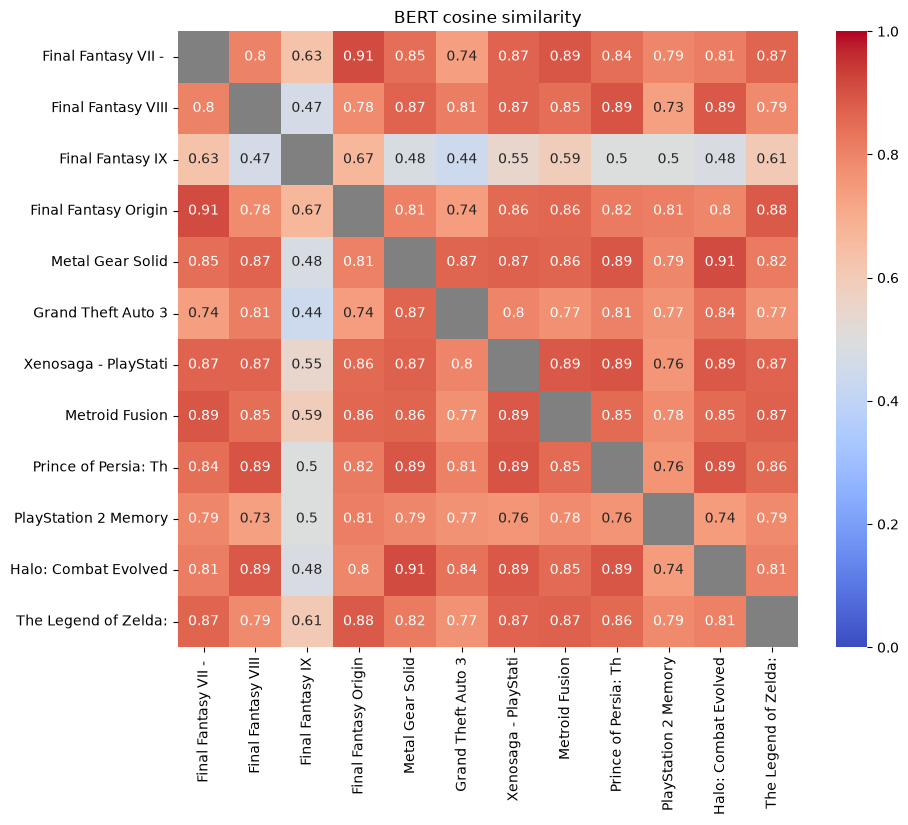

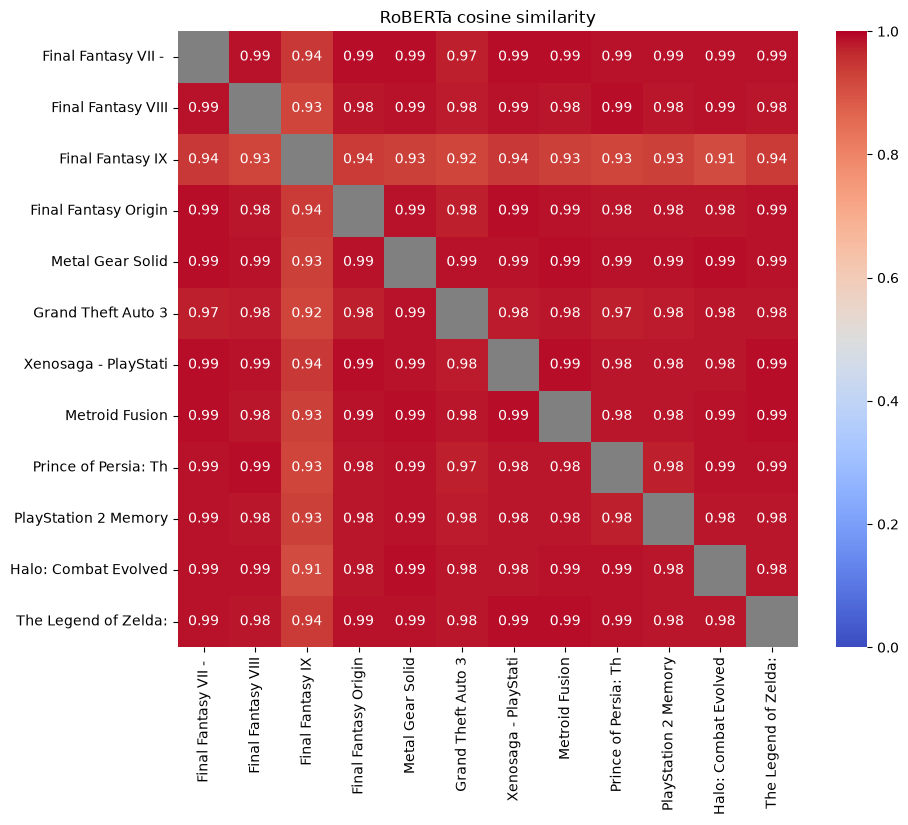

In [7]:
selected_item_ids = [
    "B00000JRSB",  # Final Fantasy VII
    "B0000296O5",  # Final Fantasy VIII
    "B00004Y57G",  # Final Fantasy IX
    "B00008RUYZ",  # Final Fantasy Origins
    "B00001X50M",  # Metal Gear Solid
    "B00005O0I2",  # GTA 3
    "B00005BW7Q",  # Xenosaga
    "B00006M3R6",  # Metroid Fusion
    "B001G6063S",  # Prince of Persia: The Sands of Time
    "B00004YRQA",  # PS2 Memory Card
    "B00005NZ1G",  # Halo
    "B000084318",  # Zelda: The Wind Waker
]

for representation_name, item_vectors in description_representations.items():
    similarity_table = item_similarity_table(item_vectors, item_ids, selected_item_ids, item_titles)
    plot_similarity_heatmap(similarity_table, f"{representation_name} cosine similarity")

The smaller table used in the report:

In [8]:
item_pairs = [
    ("B00000JRSB", "B0000296O5"),  # FF7 vs FF8, expected high
    ("B00000JRSB", "B00005O0I2"),  # FF7 vs GTA 3, expected low
    ("B00000JRSB", "B00004YRQA"),  # FF7 vs PS2 memory card, expected very low
    ("B00000JRSB", "B00005NZ1G"),  # FF7 vs Halo, PlayStation vs Xbox
]
row_of_item = {item_id: row for row, item_id in enumerate(item_ids)}

pair_similarities = {}
for first_item_id, second_item_id in item_pairs:
    pair_name = f"{item_titles[first_item_id][:17]} vs {item_titles[second_item_id][:20]}"
    pair_similarities[pair_name] = {}
    for representation_name, item_vectors in description_representations.items():
        first_vector = item_vectors[[row_of_item[first_item_id]]]
        second_vector = item_vectors[[row_of_item[second_item_id]]]
        pair_similarities[pair_name][representation_name] = cosine_similarity(first_vector, second_vector)[0][0]

pd.DataFrame(pair_similarities).T.round(3)

,TF-IDF,GloVe,BERT,RoBERTa
Final Fantasy VII vs Final Fantasy VIII,0.443,0.994,0.803,0.985
Final Fantasy VII vs Grand Theft Auto 3,0.021,0.933,0.737,0.973
Final Fantasy VII vs PlayStation 2 Memory,0.024,0.842,0.793,0.986
Final Fantasy VII vs Halo: Combat Evolved,0.031,0.926,0.814,0.985


## Content-based recommendations
Each item document now combines description, categories, features and title. A user profile is the rating-weighted mean of the user's rated items, and we recommend the 10 most similar unrated items.

In [9]:
item_corpus = build_item_corpus(item_metadata_df)
corpus_tfidf_matrix, _ = fit_tfidf(item_corpus)

corpus_representations = {
    "CB TF-IDF": corpus_tfidf_matrix,
    "CB GloVe": load_or_compute_embeddings("../cache/cb_glove_corpus.npy", lambda: glove_embeddings(item_corpus)),
    "CB BERT": load_or_compute_embeddings("../cache/cb_bert_corpus.npy",
                                          lambda: transformer_embeddings(item_corpus, "bert-base-uncased")),
    "CB RoBERTa": load_or_compute_embeddings("../cache/cb_roberta_corpus.npy",
                                             lambda: transformer_embeddings(item_corpus, "roberta-base")),
}

content_based_recommendations = {}
for model_name, item_vectors in corpus_representations.items():
    content_based_recommendations[model_name] = recommend_by_profile_similarity(item_vectors, item_ids, train_df, k=10)

compare_models(content_based_recommendations, test_df)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 7000.99it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,HR,P@10,MAP@10,MRR@10,Coverage
CB TF-IDF,0.205,0.023,0.020,0.075,0.613
CB GloVe,0.092,0.010,0.009,0.035,0.227
CB BERT,0.084,0.009,0.006,0.030,0.264
CB RoBERTa,0.068,0.007,0.006,0.024,0.231
